# Encoder–HistGB: cosine annealing with warm restarts

Based on **baseline.ipynb**, using the saved winning encoder parameters from **opt.ipynb**
and HistGB parameters from **histgb_opt.ipynb**. The shared preprocessing and engineered
features come from **features_selection.ipynb**, including the two new OFF-history features.
HistGB receives these features plus one contextual encoder embedding per visit.

The encoder receives original imputed features, missingness indicators and elapsed time.
It uses bidirectional attention with no CLS token. AdamW follows 20-epoch cosine cycles
with warm restarts, for at most 150 epochs. The minimum learning rate is 1% of the initial
rate; each restart returns to the initial rate without resetting model or optimizer state.

Validation uses **five disjoint patient folds and seed 43 only**. Within each outer training
fold, 20% of patients form an internal early-stopping holdout. Keep the best encoder checkpoint
and its fitted preprocessing/scaling; there is no second encoder fit. HistGB is trained on all
outer training patients. Outer validation patients never fit preprocessing or either model.

**Saved outputs show the previous schedule until the CV cell is rerun.**


## 1. Reuse the shared baseline and set training options

Only the five setup cells from features_selection.ipynb are executed, not its validation or
feature-selection experiments. Paths work from the project root or either notebook folder.
Architecture/training constants below are the saved winner printed by opt.ipynb; HistGB
constants are the saved winner printed by histgb_opt.ipynb. No optimization is rerun here.


In [39]:
import json
import os
from pathlib import Path
from copy import deepcopy
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold

PROJECT_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / "exploration/features_selection.ipynb").is_file())
reference = json.loads((PROJECT_DIR / "exploration/features_selection.ipynb").read_text())
previous_dir = Path.cwd()
try:
    os.chdir(PROJECT_DIR)
    for i in [1, 3, 4, 6, 8]:  # Imports/data, history, imputation, features, pipeline.
        exec("".join(reference["cells"][i]["source"]))
finally:
    os.chdir(previous_dir)
DATA_DIR = PROJECT_DIR / "data"
baseline = clone(pipeline)

SEED = 42
SEEDS = [SEED]
# Saved confirmed encoder winner from opt.ipynb.
ENCODER = dict(width=32, heads=8, layers=3, dropout=0.1347886862599206,
               ff_multiplier=3, mlp_layers=2, mlp_units=16)
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 150, 25, 128
LEARNING_RATE, WEIGHT_DECAY = 0.001759366313629433, 4.3514588969246546e-05
MIN_LEARNING_RATE = LEARNING_RATE * 0.01
RESTART_PERIOD, RESTART_MULTIPLIER = 20, 1  # Constant 20-epoch cosine cycles.
# Saved best HistGB parameters from histgb_opt.ipynb; used for both comparisons.
HISTGB_PARAMS = {
    "learning_rate": 0.03471523676107423, "max_iter": 800,
    "max_leaf_nodes": 62, "min_samples_leaf": 16,
    "l2_regularization": 8.305016398991823, "max_features": 0.6408427464001498,
}
baseline[-1].set_params(random_state=SEED, **HISTGB_PARAMS)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_num_threads(3)
print(f"Device: {DEVICE}; baseline: {baseline[-1]}")

Device: mps; baseline: HistGradientBoostingRegressor(l2_regularization=8.305016398991823,
                              learning_rate=0.03471523676107423,
                              max_features=0.6408427464001498, max_iter=800,
                              max_leaf_nodes=62, min_samples_leaf=16,
                              random_state=42)


## 2. One sequence per patient

Patient IDs only group visits; they are never encoder inputs. Elapsed time encodes the actual
spacing between visits. Padding uses row number -1, which is ignored by attention and MSE.
The row numbers also restore embeddings to the original visit order after batching.

In [40]:
def encoder_features(imputed):
    features = imputed.drop(columns="patient_id").copy()
    features["time_since_first_visit"] = (
        imputed["age"] - imputed.groupby("patient_id")["age"].transform("min")
    )
    return features


def patient_sequences(raw, features, targets=None):
    visits = raw.reset_index(drop=True).sort_values(["patient_id", "age"])
    rows = [torch.tensor(group.index.to_numpy())
            for _, group in visits.groupby("patient_id", sort=False)]
    values = torch.tensor(np.asarray(features), dtype=torch.float32)
    labels = torch.tensor(np.zeros(len(raw)) if targets is None else np.asarray(targets),
                          dtype=torch.float32)
    return TensorDataset(
        pad_sequence([values[i] for i in rows], batch_first=True),
        pad_sequence([labels[i] for i in rows], batch_first=True),
        pad_sequence(rows, batch_first=True, padding_value=-1),
    )

## 3. Optimized bidirectional encoder

Dense input projection → three TransformerEncoder layers → one embedding per visit.
Use the same parameterized architecture as opt.ipynb: width 32, eight heads, feed-forward
multiplier three, and a regression head with two hidden layers of 16 units. The regression
head supervises training; HistGB receives the contextual embeddings.


In [41]:
class VisitEncoder(nn.Module):
    def __init__(self, n_features, width=64, heads=4, layers=2, dropout=0.1,
                 ff_multiplier=2, mlp_layers=0, mlp_units=32):
        super().__init__()
        self.projection = nn.Linear(n_features, width)
        layer = nn.TransformerEncoderLayer(
            d_model=width, nhead=heads, dim_feedforward=ff_multiplier * width,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=layers,
                                             enable_nested_tensor=False)
        # 1. Initialize the encoder’s weights
        # TransformerEncoder copies its layer: give each block independent weights.
        for parameter in self.encoder.parameters():
            if parameter.ndim > 1:
                nn.init.xavier_uniform_(parameter)
        # 2. Build the regression head
        head, input_dim = [], width
        for _ in range(mlp_layers):
            head.extend([nn.Linear(input_dim, mlp_units), nn.GELU(), nn.Dropout(dropout)])
            input_dim = mlp_units
        self.head = nn.Sequential(*head, nn.Linear(input_dim, 1))

    def encode(self, values, padding):
        return self.encoder(self.projection(values), src_key_padding_mask=padding,
                            is_causal=False)

    def forward(self, values, padding):
        return self.head(self.encode(values, padding)).squeeze(-1)

## 4. Cosine annealing with warm restarts and an internal patient holdout

Fit the encoder's imputation, input scaling and target scaling on the internal training patients
only. Train AdamW with CosineAnnealingWarmRestarts (T_0=20, T_mult=1,
eta_min=1% of the initial learning rate), stepping the scheduler once per epoch after
the optimizer updates. Each cycle lasts 20 epochs; model weights and optimizer state
continue across restarts. The history records the rate actually used in each epoch
and MSE in OFF score units.

Early stopping monitors the internal holdout with PATIENCE=25 across all cycles. Restore and freeze the best
checkpoint, retaining its matching preprocessing and scalers. There is no encoder refit on
all fold-training patients. HistGB can still train on all outer training patients using embeddings
from this frozen encoder. No outer validation target is used for stopping.


In [42]:
def train_network(training, seed, epochs, validation=None):
    torch.manual_seed(seed)
    network = VisitEncoder(training.tensors[0].shape[-1], **ENCODER).to(DEVICE)
    optimizer = torch.optim.AdamW(network.parameters(), lr=LEARNING_RATE,
                                 weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=RESTART_PERIOD, T_mult=RESTART_MULTIPLIER,
        eta_min=MIN_LEARNING_RATE,
    )
    loader = DataLoader(training, batch_size=BATCH_SIZE, shuffle=True)
    best_loss, best_epoch, best_state, stale = np.inf, epochs, None, 0
    history = []

    for epoch in range(1, epochs + 1):
        network.train()
        total_error, count = 0.0, 0
        for values, targets, rows in loader:
            values, targets, rows = (t.to(DEVICE) for t in (values, targets, rows))
            valid = rows >= 0
            optimizer.zero_grad()
            prediction = network(values, ~valid)
            loss = nn.functional.mse_loss(prediction[valid], targets[valid])
            loss.backward()
            nn.utils.clip_grad_norm_(network.parameters(), 1.0)
            optimizer.step()
            total_error += loss.item() * valid.sum().item()
            count += valid.sum().item()
        history.append({"epoch": epoch, "train_MSE": total_error / count,
                        "learning_rate": optimizer.param_groups[0]["lr"]})

        if validation is not None:
            network.eval()
            total_error, count = 0.0, 0
            with torch.no_grad():
                for values, targets, rows in DataLoader(validation, batch_size=BATCH_SIZE):
                    values, targets, rows = (t.to(DEVICE) for t in (values, targets, rows))
                    valid = rows >= 0
                    prediction = network(values, ~valid)
                    total_error += ((prediction[valid] - targets[valid]) ** 2).sum().item()
                    count += valid.sum().item()
            stop_loss = total_error / count
            history[-1]["stop_MSE"] = stop_loss
            if stop_loss < best_loss:
                best_loss, best_epoch, stale = stop_loss, epoch, 0
                best_state = deepcopy(network.state_dict())
            else:
                stale += 1
            if stale >= PATIENCE:
                break
        scheduler.step()

    if best_state is not None:
        network.load_state_dict(best_state)
    return network.eval(), best_epoch, pd.DataFrame(history)


def fit_encoder(raw, targets, seed):
    fit_idx, stop_idx = next(GroupShuffleSplit(
        n_splits=1, test_size=0.2, random_state=seed
    ).split(raw, groups=raw["patient_id"]))
    fit_raw, stop_raw = raw.iloc[fit_idx], raw.iloc[stop_idx]
    inner_prep = clone(baseline[:2])
    fit_features = encoder_features(inner_prep.fit_transform(fit_raw))
    stop_features = encoder_features(inner_prep.transform(stop_raw))
    scaler = StandardScaler().fit(fit_features)
    mean = targets.iloc[fit_idx].mean()
    scale = max(targets.iloc[fit_idx].std(ddof=0), 1e-8)
    training = patient_sequences(fit_raw, scaler.transform(fit_features),
                                 (targets.iloc[fit_idx] - mean) / scale)
    stopping = patient_sequences(stop_raw, scaler.transform(stop_features),
                                 (targets.iloc[stop_idx] - mean) / scale)
    network, epochs, history = train_network(training, seed, MAX_EPOCHS, stopping)
    history[["train_MSE", "stop_MSE"]] *= scale ** 2

    network.requires_grad_(False)
    return dict(network=network, prep=inner_prep, scaler=scaler,
                target_mean=mean, target_scale=scale,
                epochs=epochs, history=history)

## 5. Extract frozen embeddings in the original row order

The prediction head stays available for diagnostics; HistGB receives only the contextual
embeddings, with no CLS token, pooling or predicted-score column. Encoder inputs are
transformed using the preprocessing retained with the best checkpoint.

In [43]:
@torch.no_grad()
def encoder_outputs(fitted, raw):
    imputed = fitted["prep"].transform(raw)
    features = fitted["scaler"].transform(encoder_features(imputed))
    sequences = patient_sequences(raw, features)
    network = fitted["network"].eval()
    embeddings = np.empty((len(raw), network.projection.out_features), dtype=np.float32)
    predictions = np.empty(len(raw), dtype=np.float32)
    for values, _, rows in DataLoader(sequences, batch_size=BATCH_SIZE):
        padding = rows < 0
        hidden = network.encode(values.to(DEVICE), padding.to(DEVICE))
        prediction = network.head(hidden).squeeze(-1).cpu()
        valid_rows = rows[~padding].numpy()
        embeddings[valid_rows] = hidden.cpu()[~padding].numpy()
        predictions[valid_rows] = prediction[~padding].numpy()
    embeddings = pd.DataFrame(embeddings, index=raw.index,
                              columns=[f"enc_{i:02d}" for i in range(embeddings.shape[1])])
    predictions = predictions * fitted["target_scale"] + fitted["target_mean"]
    return embeddings, pd.Series(predictions, index=raw.index)

## 6. Five-fold patient-separated Encoder–HistGB validation

GroupKFold with five folds and seed 43 assigns every patient to exactly one outer validation
fold. The same seed controls encoder initialization, the internal patient holdout and HistGB.
For each fold, retain the best early-stopped encoder, freeze it, append its embeddings and
fit HistGB on all outer training patients. Its imputer and scaler stay fitted on the internal
training patients; the HistGB preprocessing is fitted on all outer training patients.

Both HistGB comparisons use the saved tuned parameters. Negative delta_MSE means embeddings
help. The standard deviation describes variability across the five folds. These folds differ
from the repeated GroupShuffleSplit holdouts in baseline.ipynb, so old scores are not paired
comparisons. Architectures and HistGB parameters were selected previously; these results are
for comparison, not an independent estimate of a model selected without validation reuse.

Each fold plots encoder training and internal validation MSE between 0 and 20, marking
the selected best epoch. A second panel shows the learning rate and its warm restarts.
Histories are retained in fold_histories[(fold, seed)].


Fold 1/5, seed 42, 133 epochs: HistGB 12.0541 → Encoder–HistGB 7.4586


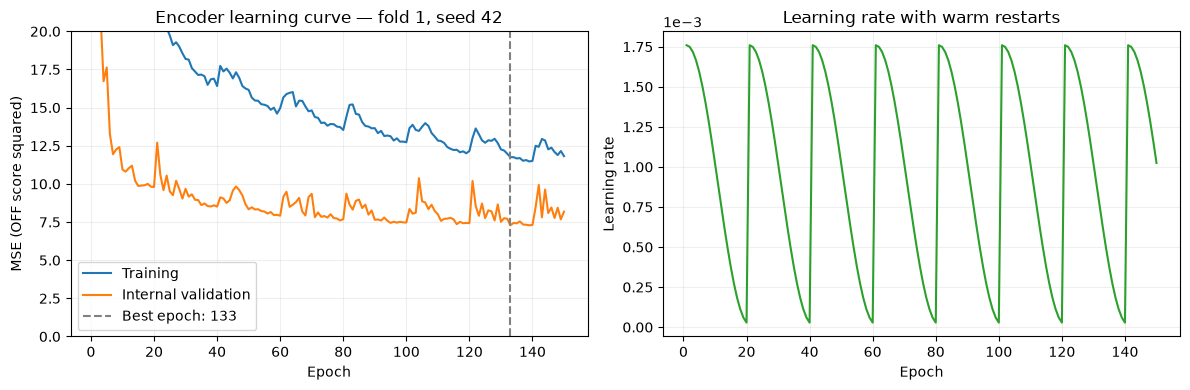

Fold 2/5, seed 42, 140 epochs: HistGB 11.7141 → Encoder–HistGB 7.5939


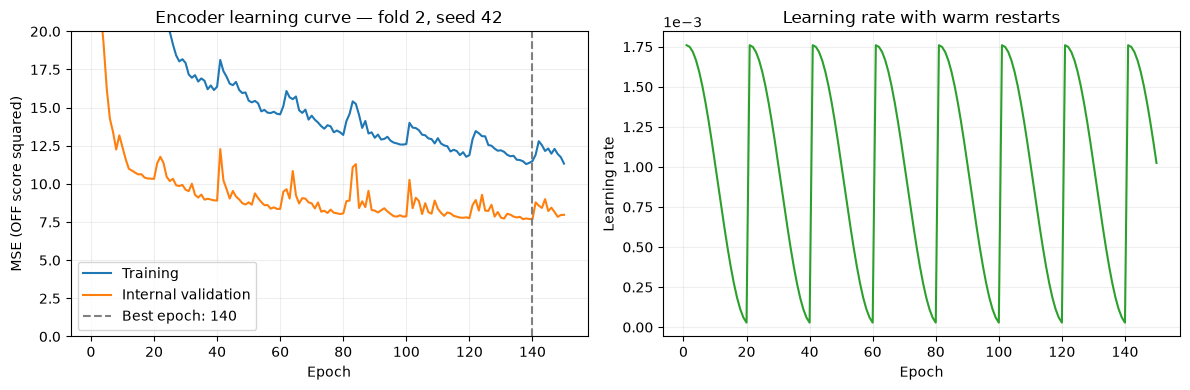

Fold 3/5, seed 42, 139 epochs: HistGB 11.2573 → Encoder–HistGB 7.5635


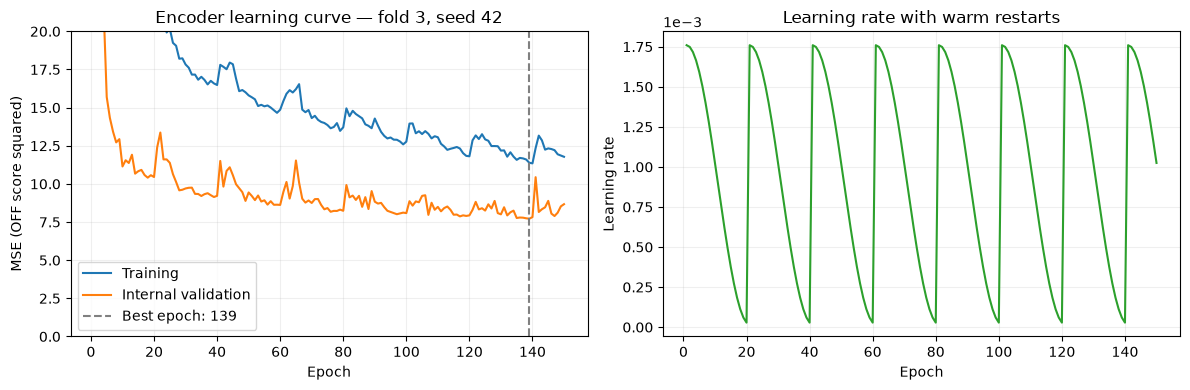

Fold 4/5, seed 42, 136 epochs: HistGB 12.1746 → Encoder–HistGB 8.0571


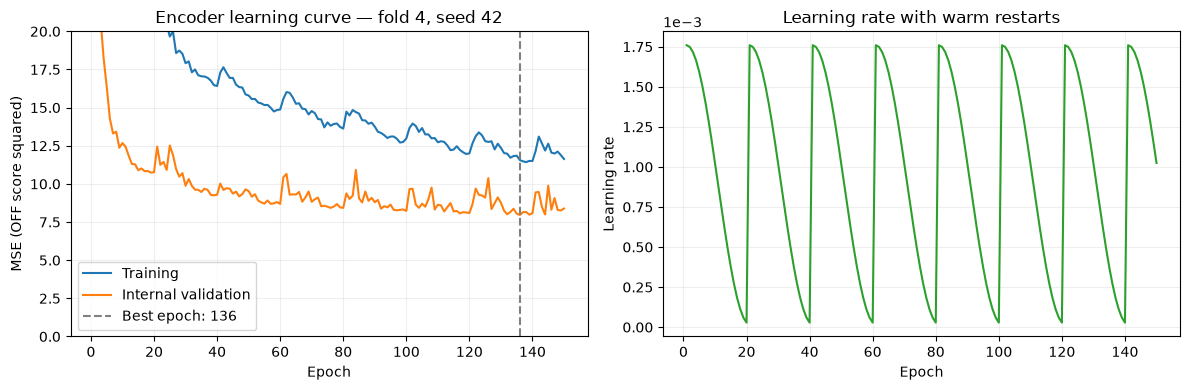

Fold 5/5, seed 42, 140 epochs: HistGB 11.5433 → Encoder–HistGB 7.4860


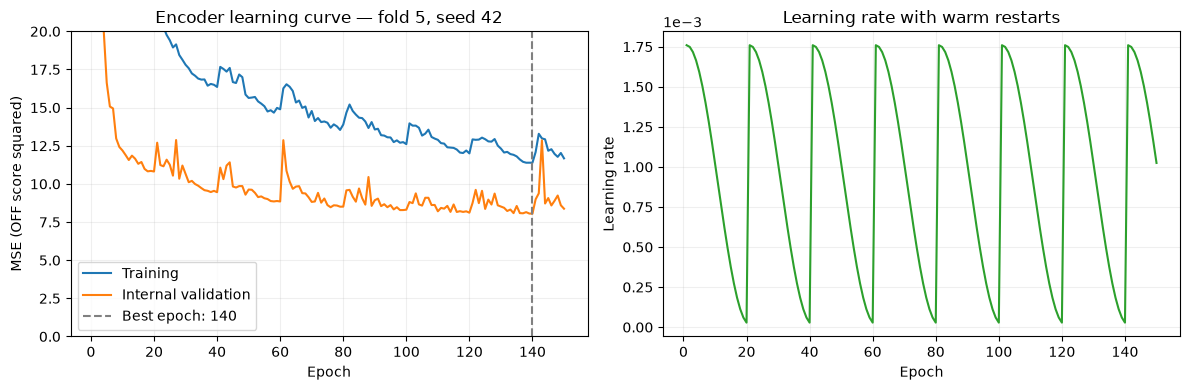

,fold,seed,epochs,HistGB,Transformer,Encoder_HistGB,delta_MSE
0,1,42,133,12.054104,7.538147,7.458590,-4.595514
1,2,42,140,11.714058,7.632703,7.593948,-4.120110
2,3,42,139,11.257284,7.660380,7.563527,-3.693757
3,4,42,136,12.174552,7.775594,8.057128,-4.117424
4,5,42,140,11.543283,7.437462,7.486035,-4.057247


In [44]:
import matplotlib.pyplot as plt

cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = []
fold_histories = {}
with threadpool_limits(limits=3):
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=X["patient_id"]), 1):
        raw_train, raw_val = X.iloc[train_idx], X.iloc[val_idx]
        yt, yv = y.iloc[train_idx], y.iloc[val_idx]
        prep = clone(baseline[:-1])
        train = prep.fit_transform(raw_train, yt)
        validation = prep.transform(raw_val)
        original = clone(baseline[-1]).fit(train, yt)
        baseline_mse = mean_squared_error(yv, original.predict(validation))

        for seed in SEEDS:
            fitted_encoder = fit_encoder(raw_train, yt, seed)
            z_train, _ = encoder_outputs(fitted_encoder, raw_train)
            z_val, encoder_prediction = encoder_outputs(fitted_encoder, raw_val)
            augmented = clone(baseline[-1]).fit(train.join(z_train), yt)
            mse = mean_squared_error(yv, augmented.predict(validation.join(z_val)))
            scores.append(dict(fold=fold, seed=seed, epochs=fitted_encoder["epochs"],
                               HistGB=baseline_mse, Transformer=mean_squared_error(yv, encoder_prediction),
                               Encoder_HistGB=mse, delta_MSE=mse - baseline_mse))
            print(f"Fold {fold}/5, seed {seed}, {fitted_encoder['epochs']} epochs: "
                  f"HistGB {baseline_mse:.4f} → Encoder–HistGB {mse:.4f}")

            history = fitted_encoder["history"].copy()
            fold_histories[(fold, seed)] = history
            fig, (ax, lr_ax) = plt.subplots(1, 2, figsize=(12, 4))
            ax.plot(history["epoch"], history["train_MSE"], label="Training")
            ax.plot(history["epoch"], history["stop_MSE"], label="Internal validation")
            ax.axvline(fitted_encoder["epochs"], color="gray", linestyle="--",
                       label=f"Best epoch: {fitted_encoder['epochs']}")
            ax.set(title=f"Encoder learning curve — fold {fold}, seed {seed}",
                   xlabel="Epoch", ylabel="MSE (OFF score squared)")
            ax.set_ylim(0, 20)
            ax.grid(alpha=0.2)
            ax.legend()
            lr_ax.plot(history["epoch"], history["learning_rate"], color="tab:green")
            lr_ax.set(title="Learning rate with warm restarts",
                      xlabel="Epoch", ylabel="Learning rate")
            lr_ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
            lr_ax.grid(alpha=0.2)
            fig.tight_layout()
            plt.show()
scores = pd.DataFrame(scores)
scores

In [45]:
summary = scores[["HistGB", "Transformer", "Encoder_HistGB"]].agg(
    ["mean", lambda s: s.std(ddof=0)]
).T
summary.columns = ["MSE", "std"]
summary["RMSE"] = np.sqrt(summary["MSE"])
summary["gain_MSE_pct"] = 100 * (1 - summary["MSE"] / summary.loc["HistGB", "MSE"])
summary

,MSE,std,RMSE,gain_MSE_pct
HistGB,11.748656,0.334517,3.427631,0.000000
Transformer,7.608857,0.114368,2.758416,35.236361
Encoder_HistGB,7.631846,0.218287,2.762580,35.040691


## 6b. Fixed 139-epoch refit on all fold-training patients

Run after section 6 has completed. Reuse its exact outer patient folds, current SEEDS and
model parameters. For each fold, fit preprocessing/scaling on all fold-training patients and
train one fresh encoder for exactly 139 epochs with the same warm-restart schedule. There is
no internal holdout or early stopping in this check. Freeze the encoder, extract embeddings
and fit HistGB on all fold-training rows. Outer validation patients are used only for scoring.

Compare each result with the matching checkpoint-based result from section 6. Negative
`delta_MSE` means that the fixed-epoch refit improves Encoder–HistGB. The original `scores`,
`summary` and `fold_histories` are preserved; new histories are in `fixed_epoch_histories`.
This check confirms the proposed submission procedure on existing validation folds; it does
not provide an independent test estimate after choosing 139 from these folds.


In [ ]:
FIXED_EPOCHS = 140

’
def fit_encoder_full(raw, targets, prep, seed, epochs=FIXED_EPOCHS):
    """Reuse preprocessing fitted on all fold-training patients; train without a holdout."""
    features = encoder_features(prep.transform(raw))
    scaler = StandardScaler().fit(features)
    mean, scale = targets.mean(), max(targets.std(ddof=0), 1e-8)
    training = patient_sequences(raw, scaler.transform(features), (targets - mean) / scale)
    network, _, history = train_network(training, seed, epochs, validation=None)
    history["train_MSE"] *= scale ** 2
    network.requires_grad_(False)
    return dict(network=network, prep=prep, scaler=scaler,
                target_mean=mean, target_scale=scale, epochs=epochs, history=history)


expected_keys = {(fold, seed) for fold in range(1, cv.n_splits + 1) for seed in SEEDS}
if (not isinstance(scores, pd.DataFrame)
        or len(scores) != len(expected_keys)
        or set(scores[["fold", "seed"]].itertuples(index=False, name=None)) != expected_keys):
    raise ValueError("Complete section 6 with the current SEEDS before running this paired check.")
reference_scores = scores.copy()
fixed_epoch_scores = []
fixed_epoch_histories = {}
with threadpool_limits(limits=3):
    for fold, (train_idx, val_idx) in enumerate(cv.split(X, y, groups=X["patient_id"]), 1):
        raw_train, raw_val = X.iloc[train_idx], X.iloc[val_idx]
        yt, yv = y.iloc[train_idx], y.iloc[val_idx]
        prep = clone(baseline[:-1])
        train = prep.fit_transform(raw_train, yt)
        validation = prep.transform(raw_val)

        for seed in SEEDS:
            fitted_full_encoder = fit_encoder_full(raw_train, yt, prep[:2], seed, FIXED_EPOCHS)
            z_train, _ = encoder_outputs(fitted_full_encoder, raw_train)
            z_val, encoder_prediction = encoder_outputs(fitted_full_encoder, raw_val)
            augmented = clone(baseline[-1]).fit(train.join(z_train), yt)
            mse = mean_squared_error(yv, augmented.predict(validation.join(z_val)))
            reference = reference_scores.loc[
                reference_scores["fold"].eq(fold) & reference_scores["seed"].eq(seed)
            ].iloc[0]
            fixed_epoch_scores.append(dict(
                fold=fold, seed=seed, epochs=FIXED_EPOCHS, HistGB=reference["HistGB"],
                Transformer=mean_squared_error(yv, encoder_prediction), Encoder_HistGB=mse,
            ))
            fixed_epoch_histories[(fold, seed)] = fitted_full_encoder["history"].copy()
            print(f"Fold {fold}/{cv.n_splits}, seed {seed}, fixed {FIXED_EPOCHS} epochs: "
                  f"checkpoint {reference['Encoder_HistGB']:.4f} → full-fold refit {mse:.4f} "
                  f"(delta {mse - reference['Encoder_HistGB']:+.4f})")
fixed_epoch_scores = pd.DataFrame(fixed_epoch_scores)
paired_comparison = reference_scores[["fold", "seed", "epochs", "Encoder_HistGB"]].rename(
    columns={"epochs": "checkpoint_epochs", "Encoder_HistGB": "checkpoint_MSE"}
).merge(
    fixed_epoch_scores[["fold", "seed", "epochs", "Encoder_HistGB"]].rename(
        columns={"epochs": "fixed_epochs", "Encoder_HistGB": "fixed_MSE"}
    ), on=["fold", "seed"], validate="one_to_one",
)
paired_comparison["delta_MSE"] = paired_comparison["fixed_MSE"] - paired_comparison["checkpoint_MSE"]
paired_comparison


Fold 1/5, seed 42, fixed 140 epochs: checkpoint 7.4586 → full-fold refit 7.2808 (delta -0.1778)
Fold 2/5, seed 42, fixed 140 epochs: checkpoint 7.5939 → full-fold refit 7.2668 (delta -0.3271)
Fold 3/5, seed 42, fixed 140 epochs: checkpoint 7.5635 → full-fold refit 7.4524 (delta -0.1112)
Fold 4/5, seed 42, fixed 140 epochs: checkpoint 8.0571 → full-fold refit 7.6260 (delta -0.4311)


In [ ]:
fixed_epoch_summary = paired_comparison[["checkpoint_MSE", "fixed_MSE"]].agg(
    ["mean", lambda s: s.std(ddof=0)]
).T
fixed_epoch_summary.columns = ["MSE", "std"]
fixed_epoch_summary.index = ["Internal-holdout checkpoint", f"Full-fold refit ({FIXED_EPOCHS} epochs)"]
fixed_epoch_summary["RMSE"] = np.sqrt(fixed_epoch_summary["MSE"])
fixed_epoch_summary["gain_vs_checkpoint_pct"] = 100 * (
    1 - fixed_epoch_summary["MSE"] / fixed_epoch_summary.iloc[0]["MSE"]
)
fixed_epoch_summary
